Projeto 01 - Análise Exploratória de Dados Olist
Objetivo
Analisar os dados de pedidos do marketplace Olist para entender padrões de vendas, qualidade dos dados e oportunidades de negócio.

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os


In [117]:
os.listdir("../data")

['olist_customers_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_orders_dataset.csv',
 'olist_order_items_dataset.csv',
 'olist_order_payments_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_products_dataset.csv',
 'olist_sellers_dataset.csv',
 'product_category_name_translation.csv']

Carregamento dos dados
Nesta etapa carregamos a base de pedidos do dataset Olist para entender a estrutura das informações.

In [118]:

orders = pd.read_csv("../data/olist_orders_dataset.csv")

Primeiras Linhas

In [119]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [120]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [121]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

## Análise de Valores Nulos

A base apresenta dados faltantes principalmente relacionados ao fluxo de entrega.

Os maiores volumes de valores nulos estão nas colunas:

- order_delivered_customer_date
- order_delivered_carrier_date

Isso pode indicar pedidos cancelados, pedidos em andamento ou registros de entrega não concluídos.

As colunas fundamentais para identificação dos pedidos e clientes não apresentam valores ausentes.

--------------------------------------------------------------------------

Esse é um dos gráficos mais importantes do dataset Olist.

Ele vai responder:

Quantos pedidos foram entregues?
Quantos foram cancelados?
Quantos estão em transporte?
Quantos estão processando?

In [124]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

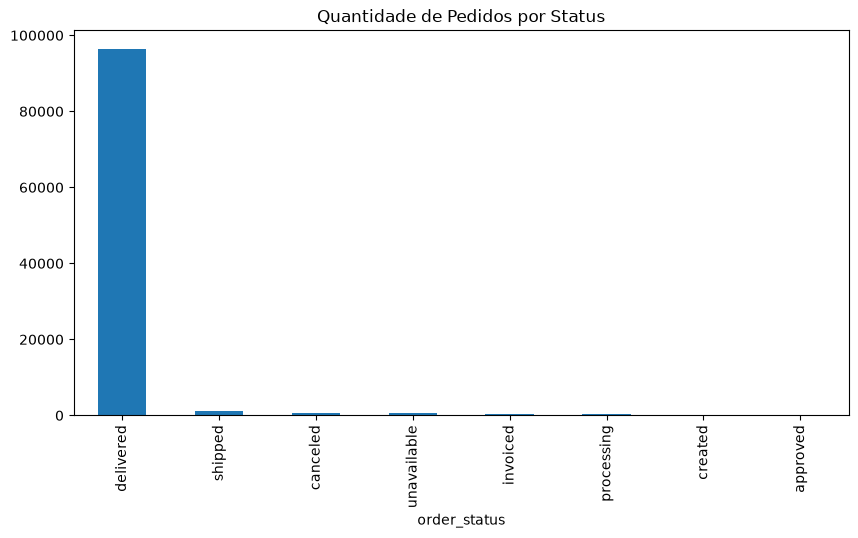

In [125]:
orders["order_status"].value_counts().plot(
    kind="bar",
    figsize=(10,5)
)
plt.title("Quantidade de Pedidos por Status")


plt.savefig(
    "../images/Quantidade_Pedidos_Status.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Análise dos Tempos de Entrega

Nesta etapa vamos calcular o tempo entre a compra e a entrega do pedido, permitindo entender a eficiência logística da operação.

In [99]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col])

In [100]:
orders["delivery_time_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.days


In [101]:
orders[
    [
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_time_days"
    ]
].head()

,order_purchase_timestamp,order_delivered_customer_date,delivery_time_days
0,2017-10-02 10:56:33,2017-10-10 21:25:13,8.0
1,2018-07-24 20:41:37,2018-08-07 15:27:45,13.0
2,2018-08-08 08:38:49,2018-08-17 18:06:29,9.0
3,2017-11-18 19:28:06,2017-12-02 00:28:42,13.0
4,2018-02-13 21:18:39,2018-02-16 18:17:02,2.0


In [102]:
orders["delivery_time_days"].describe()

count    96476.000000
mean        12.094086
std          9.551746
min          0.000000
25%          6.000000
50%         10.000000
75%         15.000000
max        209.000000
Name: delivery_time_days, dtype: float64

Esse gráfico já começa a responder:

Qual o prazo típico de entrega?
Existem entregas muito demoradas?
Existem outliers?

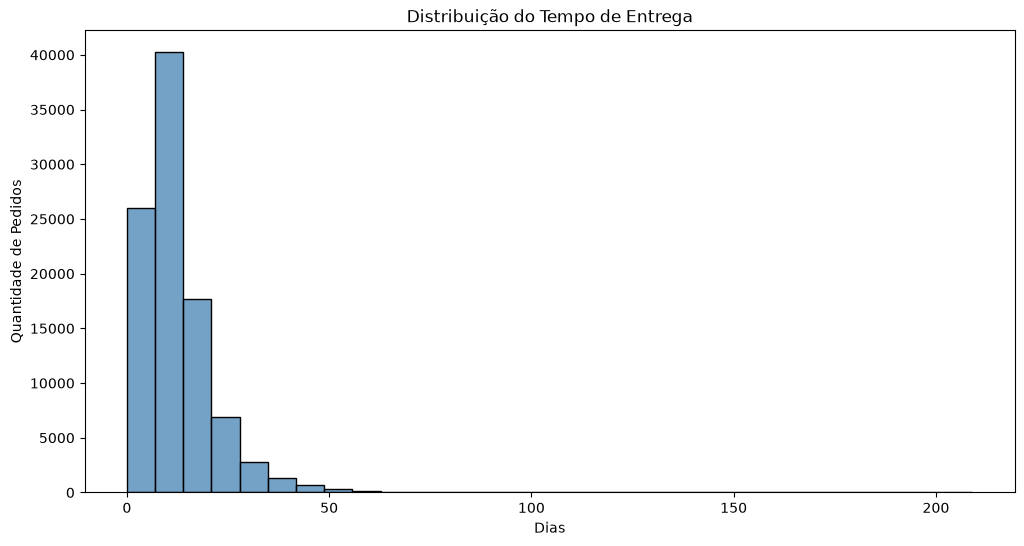

In [103]:
plt.figure(figsize=(12,6))

sns.histplot(
    orders["delivery_time_days"],
    bins=30,
    color="steelblue"
)

plt.title("Distribuição do Tempo de Entrega")
plt.xlabel("Dias")
plt.ylabel("Quantidade de Pedidos")



plt.savefig(
    "../images/distribuicao_Tempo_Entrega.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Insight Inicial

A distribuição dos tempos de entrega permite identificar o comportamento padrão da operação logística.

Pedidos com prazo muito superior à média podem indicar gargalos operacionais, problemas de transporte ou restrições geográficas.

In [104]:
media_entrega = int(orders["delivery_time_days"].mean())
mediana_entrega = int(orders["delivery_time_days"].median())
maior_entrega = int(orders["delivery_time_days"].max())
menor_entrega = int(orders["delivery_time_days"].min())

print(f"📦 Tempo médio de entrega: {media_entrega} dias")
print(f"📊 Mediana do tempo de entrega: {mediana_entrega} dias")
print(f"🚚 Maior tempo de entrega: {maior_entrega} dias")

if menor_entrega == 0:
    print("⚡ Menor prazo de entrega: no mesmo dia da compra")
else:
    print(f"⚡ Menor prazo de entrega: {menor_entrega} dias")

📦 Tempo médio de entrega: 12 dias
📊 Mediana do tempo de entrega: 10 dias
🚚 Maior tempo de entrega: 209 dias
⚡ Menor prazo de entrega: no mesmo dia da compra


In [105]:
bins = [0, 3, 7, 14, 30, 60, 365]

labels = [
    "0-3 dias",
    "4-7 dias",
    "8-14 dias",
    "15-30 dias",
    "31-60 dias",
    "60+ dias"
]

orders["delivery_group"] = pd.cut(
    orders["delivery_time_days"],
    bins=bins,
    labels=labels
)

In [106]:
orders["delivery_group"].value_counts().sort_index()

delivery_group
0-3 dias       8589
4-7 dias      25096
8-14 dias     36398
15-30 dias    22262
31-60 dias     3830
60+ dias        288
Name: count, dtype: int64

## Primeira Abordagem: Distribuição do Tempo de Entrega

Inicialmente foi utilizado um histograma para visualizar a distribuição do tempo de entrega dos pedidos.

Embora a visualização represente corretamente os dados, a interpretação não é imediata para usuários de negócio. A presença de valores extremos e a concentração de pedidos em determinadas faixas dificultam a leitura e a extração de insights relevantes.

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_11976\2222340640.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


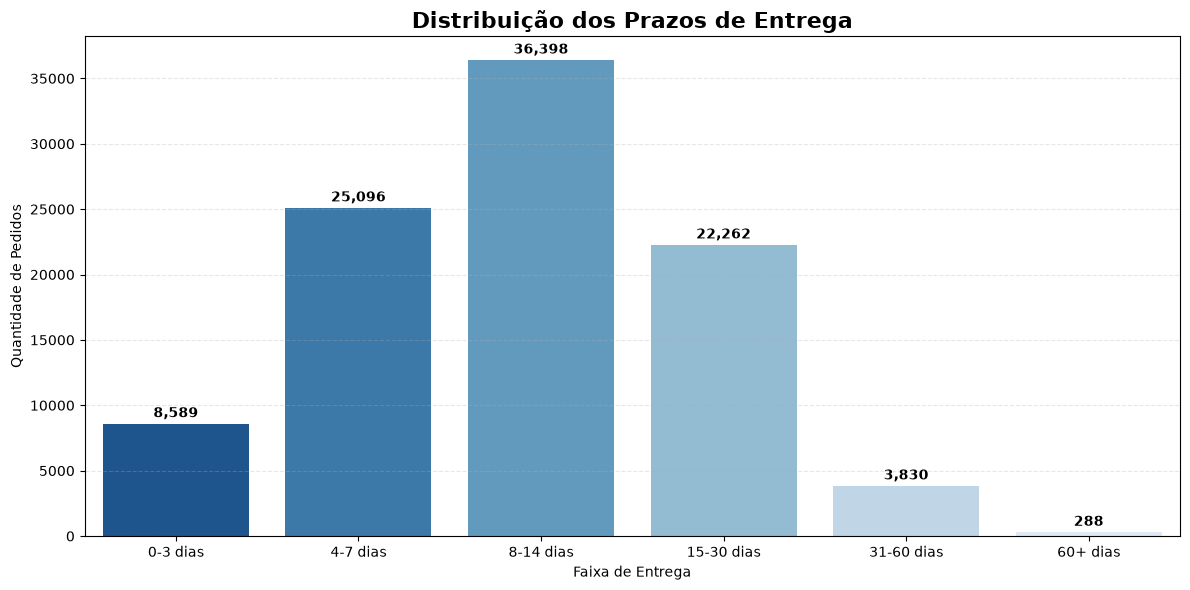

In [107]:
delivery_counts = (
    orders["delivery_group"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,6))

ax = sns.barplot(
    x=delivery_counts.index,
    y=delivery_counts.values,
    palette="Blues_r"
)

plt.title(
    "Distribuição dos Prazos de Entrega",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Faixa de Entrega")
plt.ylabel("Quantidade de Pedidos")

for i, v in enumerate(delivery_counts.values):
    ax.text(
        i,
        v + 500,
        f"{v:,.0f}",
        ha="center",
        fontweight="bold"
    )

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()



plt.savefig(
    "../images/distribuicao_Prazos_Entrega.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

## Refinamento da Visualização

Após analisar o histograma, foi identificado que a visualização não comunicava de forma clara o comportamento predominante das entregas.

Para tornar a análise mais intuitiva, os pedidos foram agrupados em faixas de prazo de entrega. Essa abordagem reduz a complexidade visual e facilita a identificação dos períodos com maior concentração de entregas.

Além disso, a nova visualização aproxima a análise da linguagem utilizada por áreas de negócio e operações logísticas, permitindo uma interpretação mais rápida dos resultados.

C:\Users\jaisler.melo\AppData\Local\Temp\ipykernel_11976\560770250.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


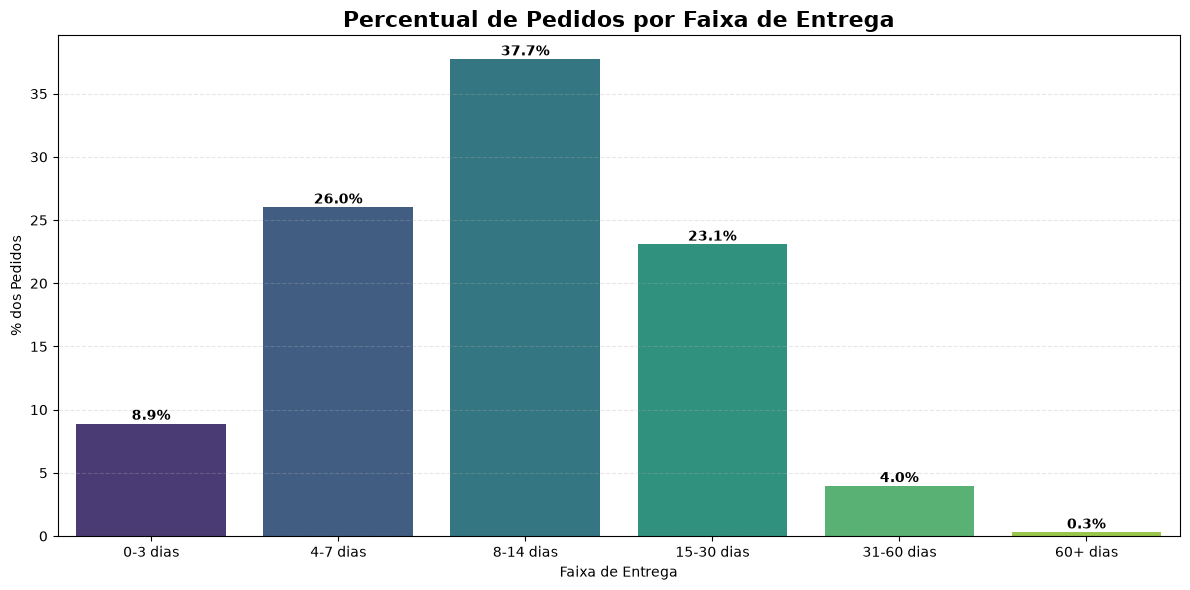

In [108]:
plt.figure(figsize=(12,6))
delivery_pct = (
    orders["delivery_group"]
    .value_counts(normalize=True)
    .mul(100)
    .sort_index()
)

delivery_pct

ax = sns.barplot(
    x=delivery_pct.index,
    y=delivery_pct.values,
    palette="viridis"
)

for i, valor in enumerate(delivery_pct.values):
    ax.text(
        i,
        valor + 0.3,
        f"{valor:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.title(
    "Percentual de Pedidos por Faixa de Entrega",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Faixa de Entrega")
plt.ylabel("% dos Pedidos")

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "../images/Percentual_Faixas_Entrega.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Principais Insights

A visualização por faixas permite observar com maior clareza o comportamento da operação logística.

Os resultados indicam que a maior parte dos pedidos foi entregue entre 8 e 14 dias, seguida pelas entregas realizadas entre 4 e 7 dias.

Também é possível identificar que entregas acima de 60 dias representam uma parcela muito pequena da operação, caracterizando situações excepcionais.

Comparada ao histograma inicial, a categorização por faixas tornou a análise mais acessível e mais adequada para comunicação executiva.

In [109]:
bins = [0, 2, 5, 10, 15, 30, 365]

labels = [
    "Até 2 dias",
    "3-5 dias",
    "6-10 dias",
    "11-15 dias",
    "16-30 dias",
    "Mais de 30 dias"
]

In [110]:
orders["delivery_delay_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_estimated_delivery_date"]
).dt.days

In [111]:
orders["delivery_delay_days"]

0        -8.0
1        -6.0
2       -18.0
3       -13.0
4       -10.0
         ... 
99436   -11.0
99437    -2.0
99438    -6.0
99439   -21.0
99440   -18.0
Name: delivery_delay_days, Length: 99441, dtype: float64

In [112]:

atrasados = (orders["delivery_delay_days"] > 0).sum()

no_prazo = (orders["delivery_delay_days"] <= 0).sum()

taxa_atraso = (
    (orders["delivery_delay_days"] > 0).mean() * 100
)

print(f"🚨 Pedidos atrasados: {atrasados}")
print(f"✅ Pedidos no prazo: {no_prazo}")
print(f"📦 Taxa de pedidos atrasados: {taxa_atraso:.1f}%")

🚨 Pedidos atrasados: 6535
✅ Pedidos no prazo: 89941
📦 Taxa de pedidos atrasados: 6.6%


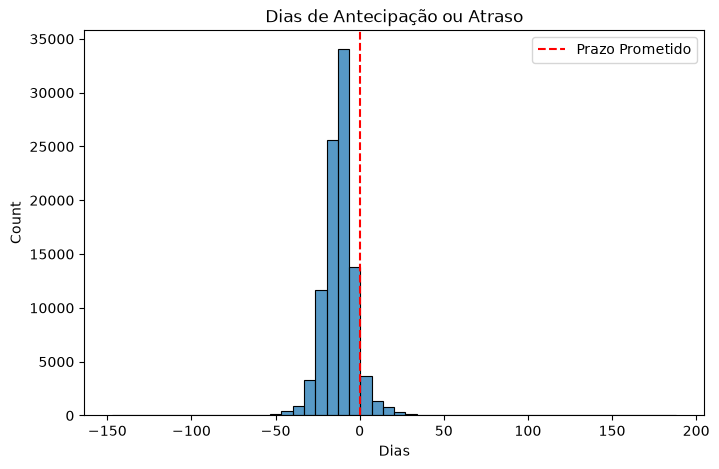

In [113]:
plt.figure(figsize=(8,5))

sns.histplot(
    orders["delivery_delay_days"],
    bins=50
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="Prazo Prometido"
)

plt.legend()
plt.title("Dias de Antecipação ou Atraso")
plt.xlabel("Dias")


plt.savefig(
    "../images/Dias_Antecipacao_Atraso.png",
    bbox_inches="tight",
    dpi=300
)
plt.show()

## Insight

A análise dos prazos mostrou que parte dos pedidos foi entregue após a data prometida ao cliente.

Esta métrica é importante para avaliar a eficiência logística e o impacto na experiência do consumidor.